Last run: 260426

Last run: 241115

Uses results from astroquery.xmatch because it has the most (conservative) matches compared to exofop or vizier cross-match methods. See details in `crossmatch_TOI_with_exofop_vizier.ipynb`.

In [1]:
import sys

!which {sys.executable}

/ut3/jerome/miniconda3/envs/wakai/bin/python


In [2]:
import sys
sys.path.insert(0, '../code')

In [3]:
import numpy as np
import pandas as pd

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

## TOI

In [4]:
from catalog import get_tois

tois = get_tois(clobber=False) #ignore Gaia_exofop & Gaia_vizier
tois.shape

(6820, 67)

In [5]:
tois.tail()

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,Stellar Mass (M_Sun) err,Sectors,Date TOI Alerted (UTC),Date TOI Updated (UTC),Date Modified,Comments,ra_deg,dec_deg,GaiaDR3_exofop,GaiaDR3_vizier
6815,410056850,7850.01,TIC 410056850.01,3,4,3,3,1,4,4,...,0.220966,101,2026-06-25,2026-06-25,2026-06-26,CTOI from Helem Salinas,320.873833,-71.238617,NaN,NaN
6816,73232401,7851.01,TIC 73232401.01,1,4,1,1,1,4,4,...,0.127735,101,2026-06-25,2026-06-25,2026-06-26,CTOI from Helem Salinas; potential L1 planet; ...,190.243708,-43.189972,NaN,NaN
6817,951438622,7852.01,NaN,5,5,5,5,1,5,5,...,NaN,101,2026-06-25,2026-06-25,2026-06-26,BD ZTF J1230-2655 b; WD host,187.568917,-26.930961,NaN,NaN
6818,341497604,7853.01,TIC 341497604.01,3,4,3,3,1,4,4,...,0.164342,101,2026-06-25,2026-06-25,2026-06-26,CTOI from Helem Salinas; low SNR; possibly evo...,318.593500,-61.295136,NaN,NaN
6819,124095894,7854.01,NaN,3,4,3,3,1,4,4,...,NaN,101,2026-06-25,2026-06-25,2026-06-26,originally alerted on TFOP FP/NPC TIC 12409588...,196.287417,-31.986914,NaN,NaN


In [6]:
tois = pd.read_csv('../data/TOIs_GaiaDR3_xmatch_new.csv')
tois.shape

(6367, 78)

In [7]:
tois.columns

Index(['TIC ID', 'TOI', 'Previous CTOI', 'Master', 'SG1A', 'SG1B', 'SG2',
       'SG3', 'SG4', 'SG5', 'ESM', 'TSM', 'Predicted Mass (M_Earth)',
       'Predicted RV Semi-amplitude (m/s)', 'Time Series Observations',
       'Spectroscopy Observations', 'Imaging Observations', 'TESS Disposition',
       'TFOPWG Disposition', 'TESS Mag', 'TESS Mag err', 'Planet Name',
       'Pipeline Signal ID', 'Source', 'Detection', 'RA', 'Dec',
       'PM RA (mas/yr)', 'PM RA err (mas/yr)', 'PM Dec (mas/yr)',
       'PM Dec err (mas/yr)', 'Epoch (BJD)', 'Epoch (BJD) err',
       'Period (days)', 'Period (days) err', 'Duration (hours)',
       'Duration (hours) err', 'Depth (mmag)', 'Depth (mmag) err',
       'Depth (ppm)', 'Depth (ppm) err', 'Planet Radius (R_Earth)',
       'Planet Radius (R_Earth) err', 'Planet Insolation (Earth Flux)',
       'Planet Equil Temp (K)', 'Planet SNR', 'Stellar Distance (pc)',
       'Stellar Distance (pc) err', 'Stellar Eff Temp (K)',
       'Stellar Eff Temp (K) err',

# exominer++ PCs

https://zenodo.org/records/15466293

In [6]:
# df_exominer = pd.read_csv('./exominerplusplus_catalog_labeled_tces_s1-s67_tess-spoc-2min_complete_1-14-2025_1039.csv')
df_exominer = pd.read_csv('./exominerplusplus_catalog_unk_tces_s1-s67_tess-spoc-2min_complete_1-16-2025_1014.csv')
df_exominer.tail()

/tmp/ipykernel_1973312/3452904129.py:2: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_exominer = pd.read_csv('./exominerplusplus_catalog_unk_tces_s1-s67_tess-spoc-2min_complete_1-16-2025_1014.csv')


,TCE ID,TIC ID,Sector Run,Planet Number,ExoMiner Score,ExoMiner Unc. Score,DV mini-report URL,Orbital Period [day],Transit Duration [hour],Transit Epoch [BTJD],Transit Depth [ppm],Planet Radius [Earth Radii],MES,Transit Model SNR,Number of transits observed,Gaia RUWE
147562,118414770-1-S9,118414770,9,1,0.0,0.0,[Download](https://mast.stsci.edu/api/v0.1/Dow...,0.427,1.584,1543.596,304.079,16.398,7.723,8.676,53.0,0.986
147563,436811829-1-S9,436811829,9,1,0.0,0.0,[Download](https://mast.stsci.edu/api/v0.1/Dow...,4.372,4.992,1543.609,368.460,2.750,35.854,-1.000,5.0,0.956
147564,140757571-1-S9,140757571,9,1,0.0,0.0,[Download](https://mast.stsci.edu/api/v0.1/Dow...,0.418,1.920,1543.316,5719.667,3.649,8.587,15.473,53.0,1.164
147565,291466214-2-S9,291466214,9,2,0.0,0.0,[Download](https://mast.stsci.edu/api/v0.1/Dow...,3.524,1.008,1544.901,0.000,13.823,82.724,-1.000,0.0,0.962
147566,141268467-1-S9,141268467,9,1,0.0,0.0,[Download](https://mast.stsci.edu/api/v0.1/Dow...,2.090,1.008,1543.878,0.000,33.542,1191.935,-1.000,0.0,0.991


In [7]:
idx = (df_exominer['Gaia RUWE']<2) & \
    (df_exominer['ExoMiner Score']>0.9) & \
    (df_exominer['Transit Depth [ppm]']>1000) & \
    (df_exominer['Transit Model SNR']>10) &\
    (df_exominer['Number of transits observed']>2) #&\
df_exominer[idx].shape

(2714, 16)

In [8]:
# csv created in crossmatch_with_GaiaDR3.ipynb
df_exominer_tic_data = pd.read_csv('../data/exominer_tic_data.csv')
df_exominer_tic_data.head()

,ID,version,HIP,TYC,UCAC,TWOMASS,SDSS,ALLWISE,GAIA,APASS,...,splists,e_RA,e_Dec,RA_orig,Dec_orig,e_RA_orig,e_Dec_orig,raddflag,wdflag,objID
0,283015592,20190415,NaN,NaN,774-000488,00035391+6446346,NaN,J000353.90+644634.5,432141093729340544,59106994.0,...,NaN,0.612413,0.437135,0.974631,64.776320,0.017667,0.016481,1.0,0,134297
1,327004130,20190415,NaN,NaN,750-002636,00133428+5953476,NaN,J001334.28+595347.5,429035557495680896,57698729.0,...,NaN,0.529875,0.369066,3.392818,59.896534,0.013967,0.013835,1.0,0,3224947
2,52052461,20190415,NaN,NaN,523-000491,00175126+1429559,1.237654e+18,J001751.28+142955.6,2768257540696946048,40712346.0,...,NaN,1.092009,1.067860,4.463744,14.498767,0.026478,0.029724,1.0,0,3987371
3,327369524,20190415,NaN,3665-00505-1,749-003047,00180577+5945582,NaN,J001805.75+594558.2,428360006379022592,57701976.0,...,NaN,0.671748,0.531758,4.523960,59.766198,0.019801,0.018777,1.0,0,4170195
4,327579226,20190415,NaN,3661-01824-1,737-003409,00185666+5712023,NaN,J001856.69+571202.3,422006585818161280,57074661.0,...,NaN,0.704855,0.537572,4.736238,57.200629,0.022038,0.019895,1.0,0,4189536


In [9]:
# Extract unique Gaia IDs and remove masked/null values
exominer_gaia_ids = [int(gid) for gid in df_exominer_tic_data['GAIA'] if gid is not np.ma.masked]
len(exominer_gaia_ids)

1456

# Perren+2023 catalog

https://ucc.ar/changelog/

* [version 260423](https://zenodo.org/records/19712053)

Manual download from zenodo and upload to server

In [4]:
import pandas as pd

df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

,Name(s),name,N_membs,r_50,r_core,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,5.17,305.52488,37.23809,75.66132,0.15836,0.5007,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.21,y
18265,XDOCC 11,xdocc11,54.0,4.3,2.57,317.73684,47.70377,89.41856,-0.28394,0.4536,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.06,n
18266,Zanin 6,zanin6,24.0,39.4,3.15,342.91235,41.33289,99.92967,-16.14552,2.6838,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.04,y
18267,Zeta Gemini,zetagemini,19.0,8.0,5.44,105.96593,20.56051,195.72326,11.87995,0.2679,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.08,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,1.16,103.73696,-5.89465,218.61444,-1.85052,3.4866,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [5]:
df = df.rename({"name": "Name",
                #"Source": "GaiaDR3",
                "probs": "Prob",
                "RA_ICRS": "ra",
                "DE_ICRS": "dec",
                "pmRA": "pmra",
                "pmDE": "pmdec",
                "Plx": "parallax",
                "RV": "radial_velocity"
                }, axis=1)
df

,Name(s),Name,N_membs,r_50,r_core,ra,dec,GLON,GLAT,parallax,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
0,ADS 12696,ads12696,11.0,6.7,8.11,294.31735,29.33689,64.00852,3.97490,0.1604,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y
1,ADS 13292,ads13292,83.0,1.0,0.40,300.59778,35.31288,71.86015,2.42440,0.5153,...,NaN,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n
2,ADS 16795;AR Cas,ads16795,25.0,88.7,2.84,351.39010,58.44167,111.87712,-2.57522,4.4213,...,39.0,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.21,y
3,AFGL333,afgl333,21.0,6.9,2.82,37.28676,61.47758,134.31242,0.77933,0.4389,...,NaN,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.11,y
4,AFGL4029,afgl4029,30.0,3.9,2.24,45.20529,60.54280,138.20570,1.56202,0.4398,...,140.0,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.06,n
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18264,XDOCC 10,xdocc10,23.0,7.4,5.17,305.52488,37.23809,75.66132,0.15836,0.5007,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.00,0.21,y
18265,XDOCC 11,xdocc11,54.0,4.3,2.57,317.73684,47.70377,89.41856,-0.28394,0.4536,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.80,0.06,n
18266,Zanin 6,zanin6,24.0,39.4,3.15,342.91235,41.33289,99.92967,-16.14552,2.6838,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.04,y
18267,Zeta Gemini,zetagemini,19.0,8.0,5.44,105.96593,20.56051,195.72326,11.87995,0.2679,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.00,0.08,y


In [6]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095682,zhbjz1,3100825448368989440,103.68109,-6.54005,3.6156,0.0238,-7.6208,0.0223,-2.2322,0.0221,21.7253,7.9802,219.12889,-2.24982,14.3220,1.7874,0.0029,0.0066,1.000
1095683,zhbjz1,3099300185222870784,103.40141,-6.89513,3.6526,0.0170,-7.4216,0.0169,-2.1923,0.0155,17.3452,9.2339,219.31911,-2.65862,12.7982,1.1791,0.0031,0.0080,1.000
1095684,zhbjz1,3101088953200869760,102.99779,-5.98813,3.6128,0.0448,-7.3251,0.0421,-2.4200,0.0400,24.7897,7.1339,218.32785,-2.60400,15.4978,2.3981,0.0041,0.0204,1.000
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [10]:
df_mem.shape

(1095686, 19)

In [13]:
df_mem.GaiaDR3.isin([2007818737548134912]).sum()

np.int64(0)

In [7]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({"name": "Name",
                        "Source": "GaiaDR3",
                        "probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem

,Name,GaiaDR3,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,radial_velocity,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,Prob
0,ads12696,2032302009643178624,294.43872,29.46409,0.1284,0.0596,-2.5152,0.0520,-4.7237,0.0588,NaN,NaN,64.17578,3.94231,17.1591,0.7457,0.0030,0.0229,0.639
1,ads12696,2032311626058484736,294.33168,29.39525,0.1829,0.1039,-2.5285,0.0772,-4.8101,0.0927,NaN,NaN,64.07007,3.99037,17.8463,0.8693,0.0049,0.0201,0.541
2,ads12696,2032303074830283520,294.12410,29.23344,0.1903,0.0456,-2.4492,0.0361,-4.5793,0.0445,NaN,NaN,63.84024,4.07026,16.5173,0.8422,0.0028,0.0064,0.344
3,ads12696,2032294691053491968,294.37134,29.21150,0.0584,0.0232,-2.5390,0.0183,-4.7135,0.0223,-104.6140,8.4782,63.92589,3.87092,15.0389,1.7402,0.0028,0.0051,0.377
4,ads12696,2032311458607201664,294.30250,29.36394,0.1469,0.0452,-2.5656,0.0362,-4.7107,0.0439,NaN,NaN,64.03026,3.99741,16.3372,0.9274,0.0028,0.0057,0.656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095681,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095682,zhbjz1,3100825448368989440,103.68109,-6.54005,3.6156,0.0238,-7.6208,0.0223,-2.2322,0.0221,21.7253,7.9802,219.12889,-2.24982,14.3220,1.7874,0.0029,0.0066,1.000
1095683,zhbjz1,3099300185222870784,103.40141,-6.89513,3.6526,0.0170,-7.4216,0.0169,-2.1923,0.0155,17.3452,9.2339,219.31911,-2.65862,12.7982,1.1791,0.0031,0.0080,1.000
1095684,zhbjz1,3101088953200869760,102.99779,-5.98813,3.6128,0.0448,-7.3251,0.0421,-2.4200,0.0400,24.7897,7.1339,218.32785,-2.60400,15.4978,2.3981,0.0041,0.0204,1.000


In [ ]:
idx = df_mem.GaiaDR3.isin(tois.GaiaDR3)
idx.sum()

In [ ]:
df_mem[idx].shape

In [14]:
idx = tois.GaiaDR3.isin(df_mem.GaiaDR3)
tois[idx].tail()

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,Teff_TIC,radial_velocity,radial_velocity_error,Teff_gaia
5165,297853363,6531.01,NaN,3,4,3,3,1,4,4,...,5.312972e+18,142.493283,-50.725218,0.870937,-8.702700,7.25329,5186.0,NaN,NaN,7363.552246
5334,379717270,6705.01,NaN,3,4,3,3,1,4,4,...,5.895009e+18,220.003897,-52.910010,2.063110,0.760646,-9.09650,6565.0,3.418663,0.567207,6222.751953
5343,460950389,6715.01,TIC 460950389.01,2,4,4,2,3,4,4,...,5.239758e+18,159.158146,-64.798275,6.622940,-17.584700,10.29910,4743.0,18.898550,3.275582,4716.540527
6046,130633912,7497.01,NaN,5,5,5,5,5,5,5,...,4.087783e+18,289.391797,-16.871609,3.250610,-0.410985,-27.28910,5555.0,42.738590,1.455883,5261.338867
6303,45636452,7761.01,NaN,3,4,3,3,1,4,4,...,5.302863e+18,130.853905,-58.512349,2.943300,-8.524130,2.78834,6035.0,22.455095,3.876165,NaN


# exominer PC but not TOI

* [Gaia DR3 1968083349388709120: also CTOI i.e. Bouma candidate](https://exofop.ipac.caltech.edu/tess/target.php?id=Gaia-DR3-1968083349388709120) <-- sometimes V-shaped; nearby@r=1.6"
* [Gaia DR3 2015547715865468288/ TIC 271759706](https://exofop.ipac.caltech.edu/tess/target.php?id=Gaia-DR3-2015547715865468288) <-- V-shaped based on ql
* [Gaia DR3 663140171661012480/ TIC 178247259](https://exofop.ipac.caltech.edu/tess/target.php?id=Gaia-DR3-663140171661012480) <-- Prot is an alias of Porb

## match by 3-,2-D separation with cluster member
* 3d match yields lower number of matches since distance/parallax is taken into account in matching
* some of parallax is negative; such are treated as nan

In [45]:
df_mem.parallax.shape, df_mem.parallax.dropna().shape

((1095686,), (1095686,))

In [46]:
(df_mem.parallax<0).sum()

np.int64(13393)

In [15]:
from astropy.coordinates import SkyCoord

# epoch already in J2016.0
toi_coords = SkyCoord(tois['RA'].values, tois['Dec'].values, 
                      distance=tois['Stellar Distance (pc)'].values, unit=('hourangle','deg','pc')) 
toi_coords

<SkyCoord (ICRS): (ra, dec, distance) in (deg, deg, pc)
    [(318.737     , -55.87186389, 375.31 ),
     ( 87.13983333, -63.98832778, 175.631),
     (312.4575    , -24.42869444, 411.211), ...,
     (235.1675    , -81.20414444, 615.776),
     (191.79995833, -43.84045833, 541.706),
     (156.873625  , -27.51553889, 346.787)]>

In [16]:
from astropy.coordinates import SkyCoord, Distance
import astropy.units as u

coords1 = SkyCoord(ra=toi_coords.ra, dec=toi_coords.dec, distance=toi_coords.distance, frame='icrs')
coords2 = SkyCoord(ra=df_mem['ra'].values*u.degree, 
                   dec=df_mem['dec'].values*u.degree, 
                   distance=Distance(parallax=df_mem['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs') 

# `match_to_catalog_sky` finds the nearest match in coords2 for each coordinate in coords1
# It returns the indices into the second catalog, the angular separation, and 3D separation (if applicable)
idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

# Add separation distance to df1
tois['sep2d_arcsec'] = d2d.to(u.arcsec).value
tois['sep3d_pc'] = d3d.to(u.pc).value
tois.sort_values('sep2d_arcsec').head()

/ut3/jerome/miniconda3/envs/wakai/lib/python3.12/site-packages/astropy/units/equivalencies.py:100: RuntimeWarning: divide by zero encountered in divide
  d = 1 / x


,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,dec,parallax,pmra,pmdec,Teff_TIC,radial_velocity,radial_velocity_error,Teff_gaia,sep2d_arcsec,sep3d_pc
5343,460950389,6715.01,TIC 460950389.01,2,4,4,2,3,4,4,...,-64.798275,6.62294,-17.58470,10.29910,4743.0,18.898550,3.275582,4716.540527,0.003245,0.132710
1228,359357695,1880.01,TIC 359357695.01,3,4,3,3,3,4,4,...,-75.131898,9.71749,-39.40120,-7.24975,3082.0,12.805389,3.309779,3373.646240,0.003672,0.444170
1298,378613125,1981.01,NaN,3,4,3,3,3,4,4,...,-63.654639,1.82301,-13.64210,4.45735,9748.0,-8.471303,3.970792,NaN,0.008235,8.082344
5077,97921547,6442.01,NaN,3,5,5,3,4,4,4,...,-35.850546,2.25521,-5.05713,6.43797,7434.0,19.647535,0.560418,7213.661133,0.009930,4.192564
1229,396368313,1882.01,TIC 396368313.01,3,4,4,3,3,4,4,...,-75.833178,1.38364,-6.75000,-5.58406,9401.0,-25.071142,9.958838,NaN,0.012406,14.049781


In [17]:
sep_2d = 3.0 * u.arcsec
sep_3d = 10 * u.pc #

# Add matching information to the original dataframes
match_mask_2d = d2d < sep_2d 
match_mask_3d = d3d < sep_3d

tois[match_mask_2d].shape, tois[match_mask_3d].shape

((39, 80), (99, 80))

In [18]:
tois[match_mask_3d][tois[match_mask_3d].sep3d_pc<1]

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,dec,parallax,pmra,pmdec,Teff_TIC,radial_velocity,radial_velocity_error,Teff_gaia,sep2d_arcsec,sep3d_pc
276,77951245,450.01,NaN,5,5,5,5,3,5,5,...,-31.412691,18.66060,34.24630,-0.734815,3160.00,NaN,NaN,NaN,0.025991,0.116741
586,460205581,837.01,NaN,3,5,5,3,4,4,4,...,-64.505259,6.98927,-18.01650,11.306800,6104.00,18.200943,0.569583,5767.977051,0.033811,0.149074
799,360156606,1227.01,NaN,3,4,4,3,4,4,4,...,-72.451804,9.90790,-40.26580,-10.641700,3055.00,11.866734,3.328678,3369.901611,0.037990,0.322189
1006,129991079,1602.01,NaN,5,5,5,5,5,5,5,...,40.891361,4.76252,18.14670,-24.997400,6175.85,-10.724714,1.045350,6033.022949,0.020716,0.868211
1009,125735470,1606.01,NaN,5,5,5,5,4,5,5,...,27.471612,6.95063,-1.07124,-20.685700,5718.00,NaN,NaN,5743.517090,710.978723,0.563975
1228,359357695,1880.01,TIC 359357695.01,3,4,3,3,3,4,4,...,-75.131898,9.71749,-39.40120,-7.249750,3082.00,12.805389,3.309779,3373.646240,0.003672,0.444170
1796,151284882,2595.01,NaN,2,5,5,2,3,4,4,...,14.356984,4.68048,6.53794,-16.124400,6033.73,24.184755,6.396424,5858.272461,0.043030,0.663998
3471,142938659,4668.01,NaN,3,4,3,3,1,4,4,...,-35.203696,9.38875,35.82320,-4.513850,3210.00,15.029994,4.083479,3479.446045,0.081469,0.187300
3839,18310799,5087.01,NaN,1,4,1,5,5,5,5,...,22.882721,16.84970,82.87420,-35.617100,4230.58,39.722755,0.374911,4550.010254,0.029172,0.360827
3848,434226736,5095.01,NaN,5,5,5,5,5,5,5,...,15.247782,22.21530,122.14800,-18.337100,3204.00,42.918736,4.105148,NaN,0.116207,0.228180


## What is the typical size of a cluster?

In [19]:
df_mem.Name.unique().shape

(18269,)

In [20]:
from catalog import get_cluster_3d_size

# test on praesepe
d = df_mem.groupby('Name').get_group('ngc2632')
get_cluster_3d_size(d)

np.float64(54.0401781647854)

In [21]:
# apply func to all clusters
df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)

/ut3/jerome/miniconda3/envs/wakai/lib/python3.12/site-packages/astropy/units/equivalencies.py:100: RuntimeWarning: divide by zero encountered in divide
  d = 1 / x
/tmp/ipykernel_2808483/3100306159.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)


In [22]:
df = df.merge(df_size.reset_index(name='extent_pc'), on='Name')
df.head()

,Name(s),Name,N_membs,r_50,r_core,ra,dec,GLON,GLAT,parallax,...,Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc,extent_pc
0,ADS 12696,ads12696,11.0,6.7,8.11,294.31735,29.33689,64.00852,3.97490,0.1604,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y,13562.040379
1,ADS 13292,ads13292,83.0,1.0,0.40,300.59778,35.31288,71.86015,2.42440,0.5153,...,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n,1932.852329
2,ADS 16795;AR Cas,ads16795,25.0,88.7,2.84,351.39010,58.44167,111.87712,-2.57522,4.4213,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.21,y,47.716982
3,AFGL333,afgl333,21.0,6.9,2.82,37.28676,61.47758,134.31242,0.77933,0.4389,...,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.11,y,1600.637192
4,AFGL4029,afgl4029,30.0,3.9,2.24,45.20529,60.54280,138.20570,1.56202,0.4398,...,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.06,n,1374.376330


In [23]:
df.extent_pc.describe()

count    1.609300e+04
mean     1.330174e+04
std      1.623937e+05
min      8.461640e+00
25%      6.201912e+02
50%      2.068683e+03
75%      6.031613e+03
max      9.997960e+06
Name: extent_pc, dtype: float64

## match by 3d separation with cluster core

In [24]:
(df['parallax']<0).sum()

np.int64(32)

In [25]:
from astropy.coordinates import SkyCoord, Distance

coords1 = SkyCoord(ra=toi_coords.ra, dec=toi_coords.dec, distance=toi_coords.distance, frame='icrs')
coords2 = SkyCoord(ra=df['ra'].values*u.degree, 
                   dec=df['dec'].values*u.degree, 
                   distance=Distance(parallax=df['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs') 

idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

tois['sep2d_arcsec'] = d2d.to(u.arcsec).value 
tois['sep3d_pc'] = d3d.to(u.pc).value
tois.sort_values('sep2d_arcsec').head()

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,dec,parallax,pmra,pmdec,Teff_TIC,radial_velocity,radial_velocity_error,Teff_gaia,sep2d_arcsec,sep3d_pc
5257,411463659,6627.01,NaN,3,4,4,3,1,4,4,...,-68.716980,1.142700,3.147990,-4.53131,6332.00,3.357300,5.504349,6561.631348,83.359546,505.767663
1748,443115574,2538.01,NaN,3,4,3,3,3,4,4,...,-7.298924,1.078780,0.504372,-3.93284,7989.00,-8.289283,4.105516,NaN,93.083115,61.684657
6192,358340733,7647.01,NaN,3,4,3,3,1,4,4,...,4.771714,1.392350,1.099920,-4.77597,6059.31,18.439142,1.930568,5996.779785,94.586661,924.607308
2160,463103749,3063.01,NaN,3,4,3,3,3,4,4,...,-58.081214,0.681203,-8.464370,4.94682,NaN,NaN,NaN,NaN,106.033118,1253.415599
5165,297853363,6531.01,NaN,3,4,3,3,1,4,4,...,-50.725218,0.870937,-8.702700,7.25329,5186.00,NaN,NaN,7363.552246,108.492537,1245.698886


In [26]:
tois.columns

Index(['TIC ID', 'TOI', 'Previous CTOI', 'Master', 'SG1A', 'SG1B', 'SG2',
       'SG3', 'SG4', 'SG5', 'ESM', 'TSM', 'Predicted Mass (M_Earth)',
       'Predicted RV Semi-amplitude (m/s)', 'Time Series Observations',
       'Spectroscopy Observations', 'Imaging Observations', 'TESS Disposition',
       'TFOPWG Disposition', 'TESS Mag', 'TESS Mag err', 'Planet Name',
       'Pipeline Signal ID', 'Source', 'Detection', 'RA', 'Dec',
       'PM RA (mas/yr)', 'PM RA err (mas/yr)', 'PM Dec (mas/yr)',
       'PM Dec err (mas/yr)', 'Epoch (BJD)', 'Epoch (BJD) err',
       'Period (days)', 'Period (days) err', 'Duration (hours)',
       'Duration (hours) err', 'Depth (mmag)', 'Depth (mmag) err',
       'Depth (ppm)', 'Depth (ppm) err', 'Planet Radius (R_Earth)',
       'Planet Radius (R_Earth) err', 'Planet Insolation (Earth Flux)',
       'Planet Equil Temp (K)', 'Planet SNR', 'Stellar Distance (pc)',
       'Stellar Distance (pc) err', 'Stellar Eff Temp (K)',
       'Stellar Eff Temp (K) err',

In [27]:
# align the two dfs
tois.shape, df.iloc[idx].shape

((6367, 80), (6367, 35))

In [28]:
# Add a prefix to matched columns to avoid confusion (optional but recommended)
col_prefix = 'matched_'
df_matched_toi = df.iloc[idx].copy().add_prefix(col_prefix)

# Concatenate horizontally
df_match = pd.concat([tois.reset_index(drop=True), 
                      df_matched_toi.reset_index(drop=True)
                      ], axis=1)

In [29]:
# make sure the 3d sep from cluster core is smaller the spatial extent of that cluster
idx2 = df_match[f'{col_prefix}extent_pc'] > df_match['sep3d_pc']
df_match[idx2]

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,matched_Mass_STDDEV,matched_Binary_fr,matched_Binary_fr_STDDEV,matched_BSS,matched_BSS_STDDEV,matched_C3,matched_P_dup,matched_UTI,matched_bad_oc,matched_extent_pc
36,25375553,143.01,NaN,5,5,5,5,5,5,5,...,NaN,NaN,NaN,NaN,NaN,CA,0.0,0.25,y,62.011263
49,149990841,167.01,NaN,3,4,3,5,3,4,4,...,NaN,NaN,NaN,NaN,NaN,DD,0.0,0.03,y,1401.195733
51,183120439,169.01,NaN,3,5,5,3,4,4,4,...,NaN,NaN,NaN,NaN,NaN,CC,0.0,0.05,y,4339.738964
53,309257814,171.01,NaN,3,5,5,3,3,4,4,...,NaN,NaN,NaN,NaN,NaN,CC,0.0,0.21,y,18534.272260
57,425997655,174.01,NaN,1,5,5,1,4,4,4,...,NaN,NaN,NaN,NaN,NaN,CD,0.0,0.13,y,1676.389183
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6361,317916466,7820.01,NaN,3,4,3,3,1,4,4,...,NaN,NaN,NaN,NaN,NaN,BB,0.0,0.15,y,72.967027
6363,146320244,7822.01,TIC 146320244.01,3,4,3,3,1,4,4,...,NaN,NaN,NaN,NaN,NaN,BB,0.0,0.19,y,27.724094
6364,1104064500,7823.01,NaN,3,4,3,3,1,4,4,...,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.17,y,11272.114058
6365,73644471,7824.01,TIC 73644471.01,3,4,3,3,1,4,4,...,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.08,y,18992.116919


In [30]:
import numpy as np

df_match['pm_diff'] =  np.sqrt((df_match[f'{col_prefix}pmra'] - df_match[f'{col_prefix}pmdec'])**2 + 
                               (df_match['PM RA (mas/yr)'] - df_match['PM Dec (mas/yr)'])**2)

In [31]:
idx3 = df_match[idx2]['pm_diff'] < 5
cols = ['TOI','matched_Name','matched_Age_[Myr]',
        'matched_extent_pc','sep3d_pc','pm_diff','TIC ID',#'GaiaDR3_exofop','GaiaDR3_vizier'
       ]
df_final = df_match[idx2].loc[idx3,cols].reset_index(drop=True)
df_final

,TOI,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,TIC ID
0,427.01,hsc1710,102.0,30.233329,19.694090,4.494703,70914192
1,474.01,platais5,60.0,67657.846715,5268.767530,2.714659,59843967
2,496.01,ngc2548,404.0,377.459546,21.226549,3.008105,88977253
3,503.01,alessi165,NaN,3838.405784,1536.884588,0.877454,186812530
4,524.01,dolidze21,178.0,25679.693246,4744.520542,2.099390,365690646
...,...,...,...,...,...,...,...
420,7775.01,hsc2915,4305.0,1037.665885,495.352926,0.523313,354809215
421,7808.01,hsc99,2667.0,6736.635238,4845.778064,4.126861,166510722
422,7816.01,ngc6737,794.0,15593.849460,3415.914118,3.785189,442381495
423,7818.01,cwnu4854,6310.0,10366.723280,8275.987431,1.953075,51217656


In [125]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({#"name": "Name",
                        "GaiaDR3": "source_id",
                        #"probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem.shape

(1095686, 19)

In [126]:
uniq = df_mem[df_mem.Name.isin(df_final.matched_Name.unique())]
counts = uniq.groupby("Name").count()
counts[counts.radial_velocity>10].sort_values('radial_velocity', ascending=False)

,source_id,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,radial_velocity,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,Prob
Name,,,,,,,,,,,,,,,,,,
ngc2548,592,592,592,592,592,592,592,592,592,230,230,592,592,592,590,592,590,592
ngc6939,1143,1143,1143,1143,1143,1143,1143,1143,1143,156,156,1143,1143,1143,1137,1143,1137,1143
ngc5662,447,447,447,447,447,447,447,447,447,134,134,447,447,447,442,447,442,447
ngc6819,2007,2007,2007,2007,2007,2007,2007,2007,2007,122,122,2007,2007,2007,1979,2007,1979,2007
ngc7209,395,395,395,395,395,395,395,395,395,106,106,395,395,395,395,395,395,395
ngc7243,510,510,510,510,510,510,510,510,510,98,98,510,510,510,508,510,508,510
upk166,386,386,386,386,386,386,386,386,386,95,95,386,386,386,384,386,384,386
alessiteutsch11,293,293,293,293,293,293,293,293,293,80,80,293,293,293,286,293,286,293
ngc1817,657,657,657,657,657,657,657,657,657,78,78,657,657,657,654,657,654,657


In [127]:
df_final[df_final.matched_Name=='ngc2548']

,TOI,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,TIC ID
2,496.01,ngc2548,404.0,377.459546,21.226549,3.008105,88977253
15,990.01,ngc2548,404.0,377.459546,304.931856,3.343032,88684250


In [128]:
df_final[df_final.TOI==496.01]

,TOI,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,TIC ID
2,496.01,ngc2548,404.0,377.459546,21.226549,3.008105,88977253


In [68]:
# target is excluded
df_final.query("TOI==6557.01")

,TOI,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,TIC ID


In [69]:
# target is excluded because extent_pc !> sep3d_pc
df_match.query("TOI==6557.01")[['TOI','matched_Name','matched_extent_pc','sep3d_pc','sep2d_arcsec','pm_diff']]

,TOI,matched_Name,matched_extent_pc,sep3d_pc,sep2d_arcsec,pm_diff
5189,6557.01,hsc2733,18.584144,22.954579,2891.087527,1.406742


In [129]:
target_gaiaid = 6000286264203417600
nearby_gaiaid = 6000286264212057344

In [130]:
# not a cluster member
df_mem.query("source_id==@target_gaiaid")

,Name,source_id,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,radial_velocity,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,Prob


Text(0.5, 0.98, 'TOI-6557 in hsc2733')

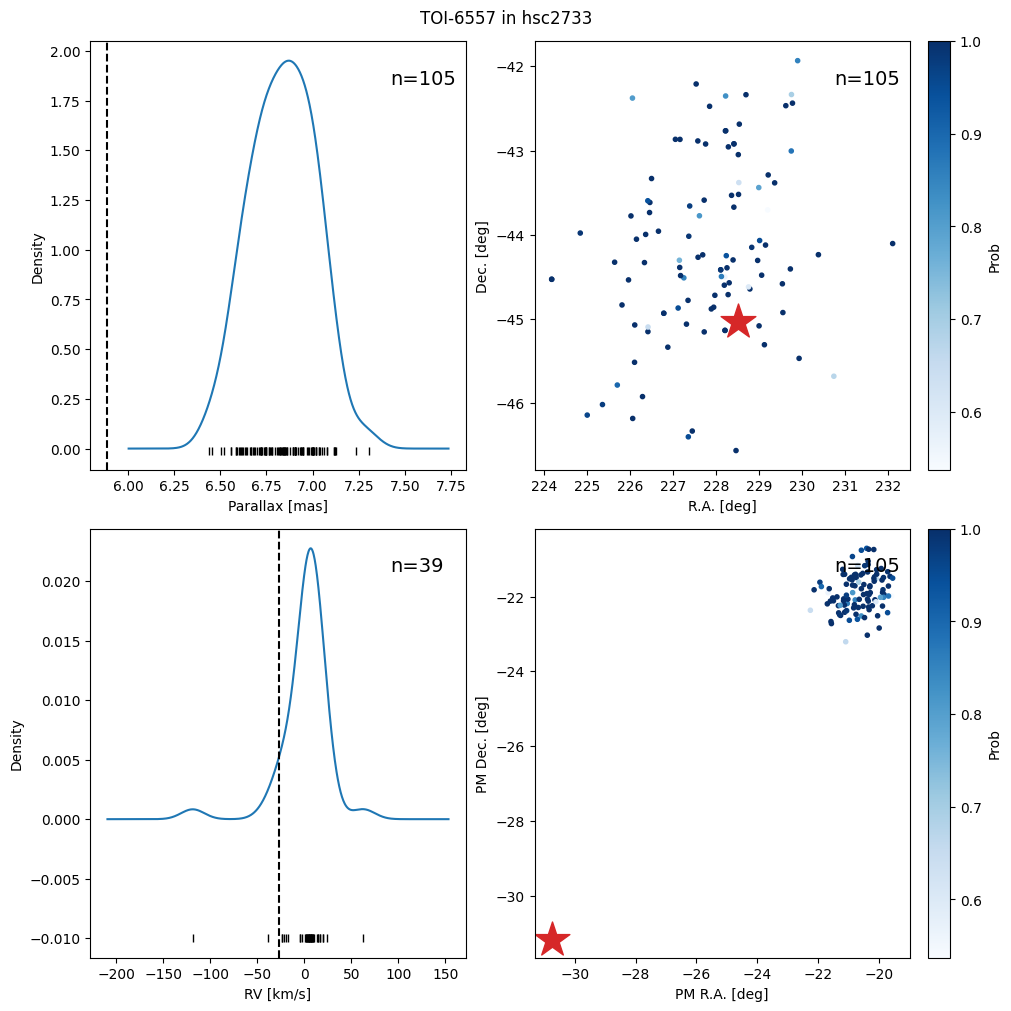

In [131]:
from catalog import plot_rdp_pmrv

toiid = 6557.01
df_target = df_match.query("TOI==@toiid").squeeze()
age = df_target["matched_Age_[Myr]"]
cname = df_target["matched_Name"]
d = df_mem.groupby("Name").get_group(cname)

fig = plot_rdp_pmrv(d,
                   color='Prob', 
                    target_gaiaid=6000286264203417600,
                    match_id=False,
                   df_target=df_target,
                   target_color="C3",
                   marker='.',
                   cmap="Blues");
fig.suptitle(f"TOI-{int(toiid)} in {cname}")

In [132]:
get_cluster_3d_size(d)

np.float64(18.584144039977314)

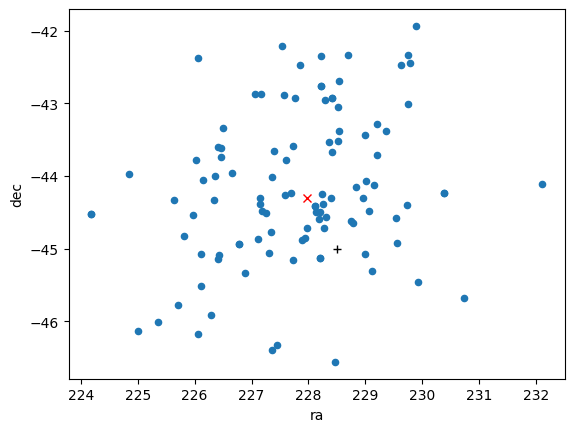

In [133]:
import matplotlib.pyplot as pl

ax = d.plot.scatter(x='ra',y='dec')
ax.plot(df.query("Name==@cname").squeeze().ra, df.query("Name==@cname").squeeze().dec, 'rx')
ax.plot(df_target.ra, df_target.dec, 'k+')

https://exofop.ipac.caltech.edu/tess/nearbytarget.php?id=141074654

Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Plotted 105 stars. Target(s): None


Text(0.5, 0.98, 'TOI-6557 in hsc2733 (14 Myr)')

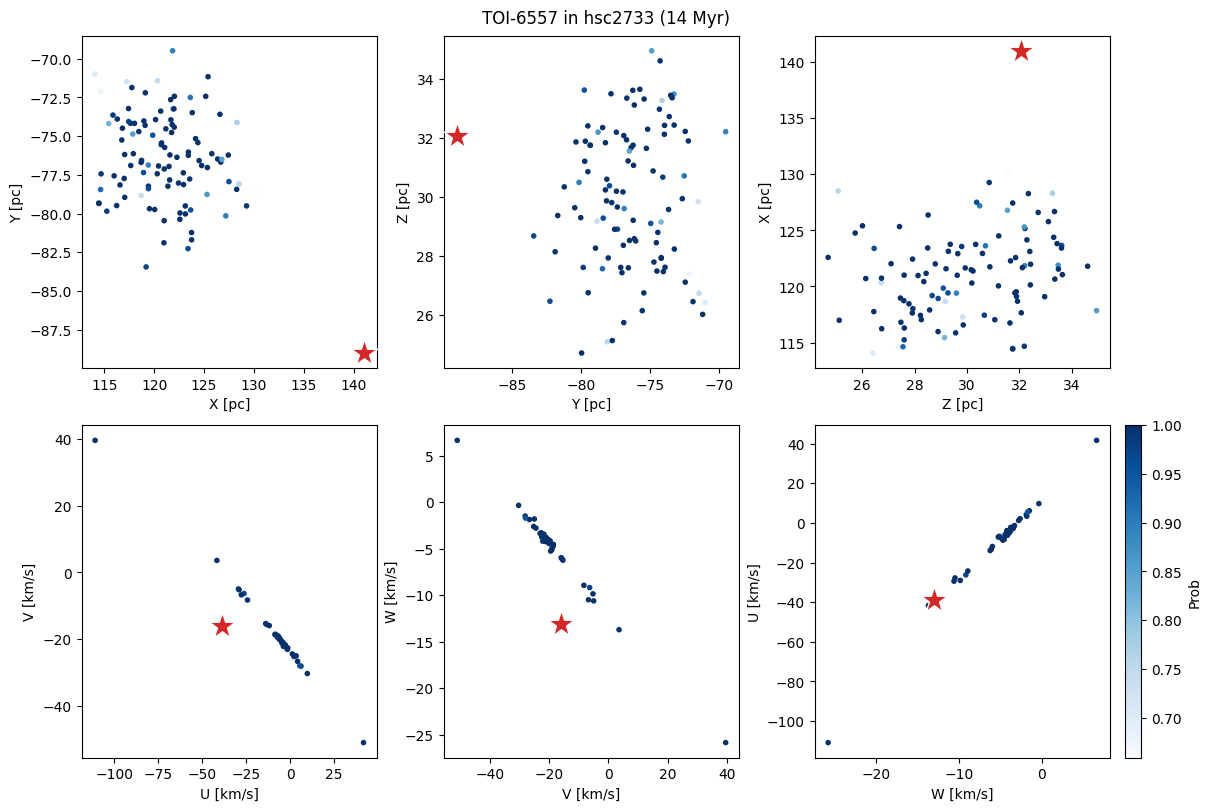

In [134]:
from catalog import plot_xyz_uvw

fig, ax = plot_xyz_uvw(d, 
                       color='Prob', 
                       df_target=df_target,
                       # target_gaiaid=target_gaiaid,
                       match_id=True,
                       target_color="C3",
                       target_ms=20,
                       marker='.',
                       cmap="Blues");
fig.suptitle(f"TOI-{int(toiid)} in {cname} ({age:.0f} Myr)")

In [76]:
df_match['source_id'] = df_match.GaiaDR3_exofop.copy()

In [ ]:
import matplotlib.pyplot as pl
from catalog import plot_rdp_pmrv
from catalog import plot_xyz_uvw
from pathlib import Path

outdir = './toi_near_clusters'
overwrite = False
groups = df_mem.groupby("Name")
for i,row in df_final.sort_values('TOI', ascending=False).iterrows():
    try:
        toi = row["TOI"]
        toiid = str(int(toi)).zfill(4)
        df_target = df_match.query("TOI==@toi").squeeze()
        cname = row["matched_Name"]
        age = row["matched_Age_[Myr]"]
        d = groups.get_group(cname)
        if len(d.radial_velocity.dropna())<10:
            print(f"Skipping TOI {toiid}")
            continue
        fp = f'{outdir}/TOI-{toiid}_in_{cname}_{age:.0f}Myr'
        
        if not Path(fp+'.png').exists() or overwrite:
            fig = plot_rdp_pmrv(d,
                               color='Prob', 
                               target_gaiaid=target_gaiaid,
                               match_id=False,
                               df_target=df_target,
                               target_color="C3",
                               marker='.',
                               cmap="Blues");
            fig.suptitle(f"TOI-{toiid} in {cname} ({age:.0f} Myr)")
            fig.savefig(fp+'.png', bbox_inches='tight', dpi=200)
        if not Path(fp+'_xyzuvw.png').exists() or overwrite:
            fig, ax = plot_xyz_uvw(d, 
                               color='Prob', 
                               df_target=df_target,
                               target_color="C3",
                               target_ms=20,
                               marker='.',
                               cmap="Blues",
                               verbose=False
                              );
            fig.suptitle(f"TOI-{toiid} in {cname} ({age:.0f} Myr)")
            fig.savefig(fp+'_xyzuvw.png', bbox_inches='tight', dpi=200)
        # pl.show()
        print(f"https://ucc.ar/_clusters/{cname}")
    except Exception as e:
        print(e)

In [148]:
import subprocess
import glob

# Get all PNG files in the directory
images = glob.glob(f"{outdir}/*Myr.png")

# Run the command securely using subprocess
subprocess.run(["img2pdf"] + sorted(images) + ["-o", f"{outdir}.pdf"])

Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.


CompletedProcess(args=['img2pdf', './toi_near_clusters/TOI-0496_in_ngc2548_404Myr.png', './toi_near_clusters/TOI-0885_in_upk442_84Myr.png', './toi_near_clusters/TOI-0990_in_ngc2548_404Myr.png', './toi_near_clusters/TOI-1311_in_ngc6819_2239Myr.png', './toi_near_clusters/TOI-1882_in_upk585_93Myr.png', './toi_near_clusters/TOI-2039_in_ngc6939_1698Myr.png', './toi_near_clusters/TOI-2063_in_cwnu1115_5Myr.png', './toi_near_clusters/TOI-3167_in_ngc5662_93Myr.png', './toi_near_clusters/TOI-3687_in_upk281_126Myr.png', './toi_near_clusters/TOI-3765_in_upk322_35Myr.png', './toi_near_clusters/TOI-3779_in_upk350_132Myr.png', './toi_near_clusters/TOI-3797_in_upk350_132Myr.png', './toi_near_clusters/TOI-3947_in_pismismoreno1_12Myr.png', './toi_near_clusters/TOI-4047_in_upk226_100Myr.png', './toi_near_clusters/TOI-4455_in_ngc6819_2239Myr.png', './toi_near_clusters/TOI-4484_in_ubc1108_1820Myr.png', './toi_near_clusters/TOI-4725_in_ngc2355_955Myr.png', './toi_near_clusters/TOI-4761_in_ngc2355_955Myr.png

In [149]:
images = glob.glob(f"{outdir}/*uvw.png")

# Run the command securely using subprocess
subprocess.run(["img2pdf"] + sorted(images) + ["-o", f"{outdir}_xyzuvw.pdf"])

Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.
Image contains an alpha channel which will be stored as a separate soft mask (/SMask) image in PDF.


CompletedProcess(args=['img2pdf', './toi_near_clusters/TOI-0496_in_ngc2548_404Myr_xyzuvw.png', './toi_near_clusters/TOI-0885_in_upk442_84Myr_xyzuvw.png', './toi_near_clusters/TOI-0990_in_ngc2548_404Myr_xyzuvw.png', './toi_near_clusters/TOI-1311_in_ngc6819_2239Myr_xyzuvw.png', './toi_near_clusters/TOI-1882_in_upk585_93Myr_xyzuvw.png', './toi_near_clusters/TOI-2039_in_ngc6939_1698Myr_xyzuvw.png', './toi_near_clusters/TOI-2063_in_cwnu1115_5Myr_xyzuvw.png', './toi_near_clusters/TOI-3167_in_ngc5662_93Myr_xyzuvw.png', './toi_near_clusters/TOI-3687_in_upk281_126Myr_xyzuvw.png', './toi_near_clusters/TOI-3765_in_upk322_35Myr_xyzuvw.png', './toi_near_clusters/TOI-3779_in_upk350_132Myr_xyzuvw.png', './toi_near_clusters/TOI-3797_in_upk350_132Myr_xyzuvw.png', './toi_near_clusters/TOI-3947_in_pismismoreno1_12Myr_xyzuvw.png', './toi_near_clusters/TOI-4047_in_upk226_100Myr_xyzuvw.png', './toi_near_clusters/TOI-4455_in_ngc6819_2239Myr_xyzuvw.png', './toi_near_clusters/TOI-4484_in_ubc1108_1820Myr_xyzuvw

In [90]:
selected_toiids = [
    # 7577, #unlikely
    7214, #good
    7111, #maybe
    # 7037, #unlikely
    6997, #maybe
    6754, #good
    6462, #good
    6248, #best
    6009, #maybe
    5973, #best
    5929, #maybe
    5244, #best
    5137, #good
    5039, #maybe
    4761, #maybe
    4152 #maybe
]

In [91]:
idx = tois.TOI.astype(int).isin(selected_toiids)
cols = ['TOI', 'Depth (ppm)','Planet Radius (R_Earth)','Stellar Radius (R_Sun)','Stellar Eff Temp (K)',
        'Period (days)','Duration (hours)','TESS Mag','Sectors','Comments'
       ]
tois.loc[idx,cols].sort_values(by='TOI', ascending=False)

,TOI,Depth (ppm),Planet Radius (R_Earth),Stellar Radius (R_Sun),Stellar Eff Temp (K),Period (days),Duration (hours),TESS Mag,Sectors,Comments
6188,7214.01,9278.000000,13.945100,1.65000,6375.0,8.909375,4.595000,12.8891,"54,81",found in faint-star QLP search
6093,7111.01,5286.000000,11.209200,1.34000,6354.0,7.063428,2.056000,12.9436,"16,56,57,76,77",found in faint-star QLP search
5984,6997.01,10730.000000,10.346200,1.07000,5576.0,16.179367,3.903000,12.6255,"26,54,74",found in faint-star QLP search
5755,6754.01,10353.000000,17.653700,1.69000,7247.0,1.994310,3.316000,13.1408,"12,39,66",found in faint-star QLP search
5465,6462.01,7202.000000,14.847700,1.83000,6976.0,3.872020,3.999000,11.9319,"7,34,61",found in faint-star QLP search
5256,6248.01,8132.241544,18.891206,1.35595,6306.0,3.852893,2.204156,12.7841,"56,57",found in faint-star QLP search; Gaia DR3 RV er...
5032,6009.01,2550.000000,11.520800,2.04000,8552.3,1.550061,1.225000,10.4403,"16,56",Possible odd/even; V-shaped; centroid centered...
4997,5973.01,3842.000000,6.799410,1.23000,6238.0,3.164374,2.506000,12.4884,"16,56,57",variable host; possible odd-even
4956,5929.01,7730.000000,15.658600,1.79000,6662.0,4.607998,3.148000,12.9153,"54,55",found in faint-star QLP search
4314,5244.01,4930.000000,10.670800,1.53000,5929.0,5.082180,4.249000,12.8105,"14,15,16,41,56",found in faint-star QLP search


In [66]:
!ls /ut2/jerome/github/research/project/tql-gallery/gallery/TOI/all/qlp/TOI6248*

/ut2/jerome/github/research/project/tql-gallery/gallery/TOI/all/qlp/TOI6248_s57_qlp_sc.png
/ut2/jerome/github/research/project/tql-gallery/gallery/TOI/all/qlp/TOI6248_s57_qlp_sc_tls.h5


# cross-match TOI with Gaia DR3 using `astroquery.xmatch`

In [8]:
import pandas as pd

df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

,Name(s),name,N_membs,r_50,r_core,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,5.17,305.52488,37.23809,75.66132,0.15836,0.5007,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.21,y
18265,XDOCC 11,xdocc11,54.0,4.3,2.57,317.73684,47.70377,89.41856,-0.28394,0.4536,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.06,n
18266,Zanin 6,zanin6,24.0,39.4,3.15,342.91235,41.33289,99.92967,-16.14552,2.6838,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.04,y
18267,Zeta Gemini,zetagemini,19.0,8.0,5.44,105.96593,20.56051,195.72326,11.87995,0.2679,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.08,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,1.16,103.73696,-5.89465,218.61444,-1.85052,3.4866,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [9]:
df = df.rename({"name": "Name",
                #"Source": "GaiaDR3",
                "probs": "Prob",
                "RA_ICRS": "ra",
                "DE_ICRS": "dec",
                "pmRA": "pmra",
                "pmDE": "pmdec",
                "Plx": "parallax",
                "RV": "radial_velocity"
                }, axis=1)
df

,Name(s),Name,N_membs,r_50,r_core,ra,dec,GLON,GLAT,parallax,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
0,ADS 12696,ads12696,11.0,6.7,8.11,294.31735,29.33689,64.00852,3.97490,0.1604,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y
1,ADS 13292,ads13292,83.0,1.0,0.40,300.59778,35.31288,71.86015,2.42440,0.5153,...,NaN,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n
2,ADS 16795;AR Cas,ads16795,25.0,88.7,2.84,351.39010,58.44167,111.87712,-2.57522,4.4213,...,39.0,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.21,y
3,AFGL333,afgl333,21.0,6.9,2.82,37.28676,61.47758,134.31242,0.77933,0.4389,...,NaN,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.11,y
4,AFGL4029,afgl4029,30.0,3.9,2.24,45.20529,60.54280,138.20570,1.56202,0.4398,...,140.0,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.06,n
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18264,XDOCC 10,xdocc10,23.0,7.4,5.17,305.52488,37.23809,75.66132,0.15836,0.5007,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.00,0.21,y
18265,XDOCC 11,xdocc11,54.0,4.3,2.57,317.73684,47.70377,89.41856,-0.28394,0.4536,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.80,0.06,n
18266,Zanin 6,zanin6,24.0,39.4,3.15,342.91235,41.33289,99.92967,-16.14552,2.6838,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.04,y
18267,Zeta Gemini,zetagemini,19.0,8.0,5.44,105.96593,20.56051,195.72326,11.87995,0.2679,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.00,0.08,y


In [10]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095682,zhbjz1,3100825448368989440,103.68109,-6.54005,3.6156,0.0238,-7.6208,0.0223,-2.2322,0.0221,21.7253,7.9802,219.12889,-2.24982,14.3220,1.7874,0.0029,0.0066,1.000
1095683,zhbjz1,3099300185222870784,103.40141,-6.89513,3.6526,0.0170,-7.4216,0.0169,-2.1923,0.0155,17.3452,9.2339,219.31911,-2.65862,12.7982,1.1791,0.0031,0.0080,1.000
1095684,zhbjz1,3101088953200869760,102.99779,-5.98813,3.6128,0.0448,-7.3251,0.0421,-2.4200,0.0400,24.7897,7.1339,218.32785,-2.60400,15.4978,2.3981,0.0041,0.0204,1.000
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [11]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({"name": "Name",
                        "Source": "GaiaDR3",
                        "probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem

,Name,GaiaDR3,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,radial_velocity,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,Prob
0,ads12696,2032302009643178624,294.43872,29.46409,0.1284,0.0596,-2.5152,0.0520,-4.7237,0.0588,NaN,NaN,64.17578,3.94231,17.1591,0.7457,0.0030,0.0229,0.639
1,ads12696,2032311626058484736,294.33168,29.39525,0.1829,0.1039,-2.5285,0.0772,-4.8101,0.0927,NaN,NaN,64.07007,3.99037,17.8463,0.8693,0.0049,0.0201,0.541
2,ads12696,2032303074830283520,294.12410,29.23344,0.1903,0.0456,-2.4492,0.0361,-4.5793,0.0445,NaN,NaN,63.84024,4.07026,16.5173,0.8422,0.0028,0.0064,0.344
3,ads12696,2032294691053491968,294.37134,29.21150,0.0584,0.0232,-2.5390,0.0183,-4.7135,0.0223,-104.6140,8.4782,63.92589,3.87092,15.0389,1.7402,0.0028,0.0051,0.377
4,ads12696,2032311458607201664,294.30250,29.36394,0.1469,0.0452,-2.5656,0.0362,-4.7107,0.0439,NaN,NaN,64.03026,3.99741,16.3372,0.9274,0.0028,0.0057,0.656
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1095681,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095682,zhbjz1,3100825448368989440,103.68109,-6.54005,3.6156,0.0238,-7.6208,0.0223,-2.2322,0.0221,21.7253,7.9802,219.12889,-2.24982,14.3220,1.7874,0.0029,0.0066,1.000
1095683,zhbjz1,3099300185222870784,103.40141,-6.89513,3.6526,0.0170,-7.4216,0.0169,-2.1923,0.0155,17.3452,9.2339,219.31911,-2.65862,12.7982,1.1791,0.0031,0.0080,1.000
1095684,zhbjz1,3101088953200869760,102.99779,-5.98813,3.6128,0.0448,-7.3251,0.0421,-2.4200,0.0400,24.7897,7.1339,218.32785,-2.60400,15.4978,2.3981,0.0041,0.0204,1.000


In [12]:
import pandas as pd

# output of cross_match_TOI_with_GaiaDR3.ipynb
matches = pd.read_csv('../data/TOIs_GaiaDR3_xmatch_new.csv')
matches.tail()

,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,SG5,...,GaiaDR3,ra,dec,parallax,pmra,pmdec,Teff_TIC,radial_velocity,radial_velocity_error,Teff_gaia
6362,422037052,7821.01,NaN,3,4,3,3,1,4,4,...,2.705273e+18,341.163270,4.535160,1.18939,0.270071,-12.29690,4885.47,9.316081,3.147140,NaN
6363,146320244,7822.01,TIC 146320244.01,3,4,3,3,1,4,4,...,5.368195e+18,158.468353,-42.699476,5.04940,-63.354500,-3.04922,5394.00,44.072063,0.312078,5390.835449
6364,1104064500,7823.01,NaN,3,4,3,3,1,4,4,...,5.772151e+18,235.167702,-81.204093,1.59525,-7.620440,-11.98820,5947.00,-28.576277,1.492967,5672.374023
6365,73644471,7824.01,TIC 73644471.01,3,4,3,3,1,4,4,...,6.138710e+18,191.800047,-43.840409,1.81794,-13.837100,-11.12720,5596.10,119.467102,1.322007,5472.825684
6366,193096383,7825.01,TIC 193096383.01,3,4,3,3,1,4,4,...,5.468665e+18,156.873752,-27.515573,2.85538,-25.377200,8.12723,5549.08,7.193756,0.784203,5573.733398


In [15]:
matches.GaiaDR3.unique().shape

(6074,)

In [16]:
idx = matches.columns.isin(['ra','dec','pmra','pmdec','','radial_velocity','parallax'])
idx

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False,  True,  True,  True,
        True,  True, False,  True, False, False])

In [17]:
final = pd.merge(df_mem, matches[matches.columns[~idx]], on='GaiaDR3').sort_values(by='TOI', ascending=False)
final.head()

,Name,GaiaDR3,ra,dec,parallax,e_Plx,pmra,e_pmRA,pmdec,e_pmDE,...,Date Modified,Comments,ra_deg,dec_deg,GaiaDR3_exofop,GaiaDR3_vizier,ID,Teff_TIC,radial_velocity_error,Teff_gaia
4,cwwdl14588,5302862568373150208,130.85383,-58.51234,2.9559,0.0136,-8.4635,0.0161,2.9909,0.0176,...,2026-06-21 12:04:08,found in faint-star QLP search,130.853833,-58.512336,NaN,NaN,45636452.0,6035.0,3.876165,NaN
36,upk545,5302862568373150208,130.85383,-58.51234,2.9559,0.0136,-8.4635,0.0161,2.9909,0.0176,...,2026-06-21 12:04:08,found in faint-star QLP search,130.853833,-58.512336,NaN,NaN,45636452.0,6035.0,3.876165,NaN
26,ngc6774,4087782677845919744,289.39180,-16.87173,3.2630,0.0184,-0.4675,0.0215,-27.2935,0.0172,...,2025-09-18 12:19:01,brown dwarf EPIC 219388192 b,289.391792,-16.871728,NaN,NaN,130633912.0,5555.0,1.455883,5261.338867
18,ic2602,5239758155778687360,159.15796,-64.79823,6.6459,0.0093,-17.5861,0.0101,10.4903,0.0098,...,2025-07-31 12:59:22,host is a BY Dra variable star; low MES,159.157958,-64.798231,5.239758e+18,NaN,460950389.0,4743.0,3.275582,4716.540527
14,hsc2675,5895008644342480640,220.00390,-52.91005,2.0757,0.0167,0.9450,0.0120,-9.1417,0.0179,...,2025-07-31 12:59:22,variable host; multiple stars in pixel,220.003917,-52.910050,5.895009e+18,5.895009e+18,379717270.0,6565.0,0.567207,6222.751953


In [18]:
final.shape

(38, 90)

In [19]:
new_cols = "TOI	TIC ID	Name	GaiaDR3	Prob	TESS Disposition	TFOPWG Disposition	Comments	TESS Mag	TESS Mag err	Source_1	Detection	Epoch (BJD)	Epoch (BJD) err	Period (days)	Period (days) err	Duration (hours)	Duration (hours) err	Depth (mmag)	Depth (mmag) err	Depth (ppm)	Depth (ppm) err	Planet Radius (R_Earth)	Planet Radius (R_Earth) err	Planet Insolation (Earth Flux)	Planet Equil Temp (K)	Planet SNR	Stellar Distance (pc)	Stellar Distance (pc) err	Stellar Eff Temp (K)	Stellar Eff Temp (K) err	Stellar log(g) (cm/s^2)	Stellar log(g) (cm/s^2) err	Stellar Radius (R_Sun)	Stellar Radius (R_Sun) err	Stellar Metallicity	Stellar Metallicity err	Stellar Mass (M_Sun)	Stellar Mass (M_Sun) err	Sectors	Date TOI Alerted (UTC)	Date TOI Updated (UTC)	Date Modified	ra_deg	dec_deg	Pipeline Signal ID	RA	Dec	PM RA (mas/yr)	PM RA err (mas/yr)	PM Dec (mas/yr)	PM Dec err (mas/yr)	DR3Name	RAdeg	DEdeg	errHalfMaj	errHalfMin	errPosAng	SolID	Source_2	RandomI	e_RAdeg	e_DEdeg	RPlx	PM	RADEcor	RAPlxcor	RApmRAcor	RApmDEcor	DEPlxcor	DEpmRAcor	DEpmDEcor	PlxpmRAcor	PlxpmDEcor	pmRApmDEcor	NAL	NAC	NgAL	NbAL	gofAL	chi2AL	epsi	sepsi	Solved	APF	nueff	MatchObsA	Nper	amax	MatchObs	IPDgofha	IPDgofhp	IPDfmp	IPDfow	RUWE	Dup	o_Gmag	FG	e_FG	RFG	Gmag_y	o_BPmag	FBP	e_FBP	RFBP	e_BPmag	o_RPmag	FRP	e_FRP	RFRP	e_RPmag	E(BP/RP)	NBPcont	NBPblend	NRPcont	NRPblend	Mode	BP-G	G-RP	n_RV	o_RV	o_RVd	RVNper	RVS/N	RVgof	RVchi2	RVTdur	RVamp	RVtempTeff	RVtemplogg	RVtemp[Fe/H]	Vatmparam	vbroad	e_Vbroad	o_Vbroad	GRVSmag	e_GRVSmag	o_GRVSmag	RVSS/N	VarFlag	PQSO	PGal	PSS	Teff	b_Teff	B_Teff	logg	b_logg	B_logg	[Fe/H]	b_[Fe/H]	B_[Fe/H]	Dist	b_Dist	B_Dist	A0	b_A0	B_A0	AG	b_AG	B_AG	E(BP-RP)	b_E(BP-RP)	B_E(BP-RP)	Lib	RAJ2000	DEJ2000	e_RAJ2000	e_DEJ2000	RADEcorJ2000	Previous CTOI	Master	SG1A	SG1B	SG2	SG3	SG4	SG5	ESM	TSM	Predicted Mass (M_Earth)	Time Series Observations	Spectroscopy Observations	Imaging Observations".split('\t')

In [20]:
cnames = final.Name.unique()
cnames

array(['cwwdl14588', 'upk545', 'ngc6774', 'ic2602', 'hsc2675', 'fsr1484',
       'ocsn82', 'alessi37', 'upk369', 'hsc759', 'pleiades', 'hyades',
       'ngc2632', 'alessi13', 'upk540', 'hsc2662', 'casado20', 'oc0199',
       'cwnu129', 'hsc1553', 'ocsn306', 'theia116', 'ngc2215', 'hsc2376',
       'upk585', 'feigelson1', 'ngc1039', 'upk303', 'hsc1103', 'hsc2523',
       'hsc1634', 'ngc2516', 'ocsn254', 'ngc2548', 'hsc1900'],
      dtype=object)

In [21]:
final2 = pd.merge(df, final, on='Name').sort_values(by='Age_[Myr]', ascending=True)

In [22]:
idx = final2.Name.isin(cnames)
final2.loc[idx,['TOI','Name','Age_[Myr]','Prob']].drop_duplicates().reset_index(drop=True).sort_values(by='TOI')

,TOI,Name,Age_[Myr],Prob
5,450.01,hsc1900,27.0,1.000
30,496.01,ngc2548,404.0,1.000
2,580.01,ocsn254,11.0,0.588
22,681.01,ngc2516,138.0,1.000
9,837.01,ic2602,36.0,1.000
27,989.01,hsc1634,284.0,0.509
3,1227.01,hsc2523,14.0,1.000
15,1588.01,hsc1103,63.0,1.000
18,1602.01,upk303,88.0,1.000
25,1641.01,ngc1039,175.0,1.000


In [78]:
df_hosts = pd.read_csv("/ut2/jerome/github/research/project/TOI-6715/data/young_validated_planets_TOIs - validated_hosts.csv", 
                        skiprows=[1], comment='#').dropna(subset=['Host']).reset_index(drop=True)
# df_hosts = df_hosts[df_hosts.distance<500].reset_index(drop=True)
df_hosts.shape

(85, 38)

In [100]:
host_toiids = df_hosts.TOI.str.replace(r'\D', '', regex=True).replace('', np.nan).dropna().astype(int).unique()
host_toiids

array([6963, 1227, 6697, 6551, 6442, 2221, 1097, 1974,  837,  200, 1975,
        942, 4399,  251, 1268,  451, 1135, 1224, 2076,  815, 1807, 1098,
       2046, 2048, 1027, 4562,  179, 1683, 1726,  560, 1099, 1430, 1136,
        201, 5398,  712, 5095, 1201, 4364, 1801, 5071, 2103, 6169, 1420,
       4544])

In [108]:
idx = final2.TOI.astype(int).isin(host_toiids)
final2.loc[~idx,['TOI','Name','Age_[Myr]','Prob']].drop_duplicates().reset_index(drop=True)

,TOI,Name,Age_[Myr],Prob
0,1880.01,feigelson1,4.0,1.000
1,580.01,ocsn254,11.0,0.588
2,450.01,hsc1900,27.0,1.000
3,4510.01,upk540,31.0,1.000
4,3411.01,cwnu129,32.0,1.000
5,2595.01,ocsn306,35.0,1.000
6,6715.01,melotte102,36.0,1.000
7,2595.01,hsc1553,38.0,1.000
8,2595.01,theia116,47.0,1.000
9,1981.01,hsc2376,48.0,1.000


In [75]:
df_old = pd.read_csv('../data/Perren2023/TOIs_in_Perren2023.csv')
df_old.shape

(66, 184)

In [31]:
final[new_cols].to_csv('../data/Perren2023/TOIs_in_Perren2023.csv', index=False)

In [32]:
final[final['TIC ID']==64837857][['TOI','Period (days)','Epoch (BJD)', 'Duration (hours)']]

,TOI,Period (days),Epoch (BJD),Duration (hours)
6,6650.04,0.000000,2.459878e+06,6.426
5,6650.03,8.996513,2.460599e+06,2.842
4,6650.02,30.505563,2.460579e+06,6.967
3,6650.01,20.329213,2.460583e+06,6.584


## distance

In [19]:
import sys
sys.path.insert(0, '../code')

In [20]:
from catalog import get_tois

tois = get_tois()
tois = tois.dropna(subset=['ra_deg','dec_deg','Stellar Distance (pc)'])
tois.shape

(6481, 67)

In [22]:
df = df.dropna(subset=['ra','dec','parallax'])[df.parallax>0]
df.shape

(16691, 17)

In [23]:
df_mem = df_mem.dropna(subset=['ra','dec','parallax'])[df_mem.parallax>0]
df_mem.shape

(1035898, 19)

In [68]:
from astropy.coordinates import SkyCoord, Distance
import astropy.units as u

c1 = SkyCoord(ra=df.ra.values*u.deg, 
             dec=df.dec.values*u.deg,
             distance=Distance(parallax=df.parallax.values*u.mas)
             )
c2 = SkyCoord(ra=tois.ra_deg.values*u.deg, 
             dec=tois.dec_deg.values*u.deg,
             distance=tois['Stellar Distance (pc)'].values*u.pc
             )

sep = 20 #pc
use_2d = False
distances = []
idx = []
for c in c2:
    d = c1.separation(c).deg if use_2d else c1.separation_3d(c).pc
    if (pd.Series(d)<sep).sum()>0:
        idx.append(True)
        distances.append(min(d))
    else:
        idx.append(False)
        distances.append(np.nan)

In [50]:
tois2 = tois.loc[idx]
tois2.shape

(79, 67)

In [51]:
idx2 = []
for c in c1:
    d = c1.separation_2d(c) if use_2d else c1.separation_3d(c)
    if (pd.Series(d.pc)<distance).sum()>0:
        idx2.append(True)
    else:
        idx2.append(False)

In [52]:
names = df[idx2].Name.apply(lambda x: str(x).lower().replace(' ','').split(';')).explode().unique()
len(names)

21914

In [53]:
idx=df_mem.Name.isin(names)
idx.sum()

1018372

In [54]:
df_mem2 = df_mem[idx]
df_mem2.shape

(1018372, 19)

## visualization

In [8]:
import pandas as pd

cluster_tois = pd.read_csv('../data/Perren2023/TOIs_in_Perren2023.csv')
cluster_tois.shape

(59, 184)

In [9]:
cluster_names = cluster_tois['Name'].unique()
len(cluster_names)

49

In [10]:
idx = df_mem.Name.isin(cluster_names)

In [11]:
df_mem2 = df_mem[idx]
df_mem2.shape

(8225, 19)

In [40]:
# %load /ut3/jerome/github/research/project/wakai/notebooks/init_ipynb
import os
import sys
import matplotlib.pyplot as pl

# sys.path.insert(0, '../code')
# assert os.environ["CONDA_DEFAULT_ENV"] == 'wakai'

plotpar = {
           'font.size': 20,
           'xtick.labelsize': 16,
           'ytick.labelsize': 16,
           'xtick.direction': 'in',
           'ytick.direction': 'in',
           'xtick.color':'black',
           'ytick.color':'black',
           'xtick.major.width':2,
           'ytick.major.width':2,
           'xtick.major.size':10,
           'ytick.major.size':10,
           'xtick.minor.width':1,
           'ytick.minor.width':1,
           'xtick.minor.size':6,
           'ytick.minor.size':6,
           'axes.labelsize': 16,
           'axes.labelcolor':'black',
           'axes.labelcolor':'black',
           'axes.spines.top':True,
           'axes.spines.right':True,
           'axes.linewidth':2,
           'axes.edgecolor':'black',
           'figure.facecolor':'none',
           'legend.facecolor':'none',
           'legend.fontsize': 16,
           'text.color':'black',
           'pdf.fonttype': 42,
           #'text.usetex': False,
           }
pl.rcParams.update(plotpar)

In [70]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import numpy as np
from astropy.coordinates import SkyCoord
import astropy.units as u
from matplotlib.lines import Line2D 

def plot_cluster_density(df, cluster_tois=None, prob_threshold=0.5, 
                         bandwidth=0.3, min_members=5,plot_all_toi=False):
    """
    Plot 2D KDE contours for stellar clusters in Galactic coordinates.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing at least:
        ['Name', 'GLON', 'GLAT', 'Prob'] columns.
    prob_threshold : float, optional
        Minimum membership probability for inclusion.
    bandwidth : float, optional
        KDE bandwidth adjustment for smoothing.
    min_members : int, optional
        Minimum number of stars required to plot a cluster.
    """
    
    # Validate required columns
    x, y = 'ra', 'dec'
    p = 'Prob'
    n = 'Name'
    required_cols = {n, x, y, p}
    if not required_cols.issubset(df.columns):
        missing = required_cols - set(df.columns)
        raise ValueError(f"Missing required columns: {missing}")
    
    # Filter by membership probability
    filtered = df[df[p] >= prob_threshold].copy()
    if filtered.empty:
        raise ValueError("No stars remain after applying probability threshold.")

    custom_handles = []
    colors = plt.cm.tab10.colors # Use a color map for different clusters
    
    # Prepare plot
    fig, ax = plt.subplots(figsize=(10, 6), tight_layout=True)
    
    # Loop through clusters
    for i,(name, group) in enumerate(filtered.groupby(n)):
        if len(group) < min_members:
            continue
        #label = f"{name} (N={len(group)})"
        label = 'cluster' if i==0 else '_nolegend_'
        cluster_color = colors[i % len(colors)]
        sb.kdeplot(
            x=group[x],
            y=group[y],
            levels=3,
            fill=False,
            bw_adjust=bandwidth,
            linewidths=2,
            zorder=2,
            color=cluster_color,
            ax=ax
        )
        custom_handles.append(Line2D([0], [0], color=cluster_color, lw=2, label=label))
    ylims = ax.get_ylim()
    xlims = ax.get_xlim()
    if cluster_tois is not None:        
        s_toi = ax.scatter(cluster_tois['ra_deg'], cluster_tois['dec_deg'], marker='*',  
                   s=100, edgecolors='k', c='y', zorder=100, label='cluster TOI')
        ax.set_xlim(*xlims)
        ax.set_ylim(*ylims)
        custom_handles.append(s_toi)
    if plot_all_toi:
        s_all = ax.scatter(tois['ra_deg'], tois['dec_deg'], marker='.', c='k', alpha=0.1, zorder=1, label='TOI')
        custom_handles.append(s_all)
    ax.grid(alpha=0)
    ax.legend(handles=custom_handles, frameon=True, framealpha=1, facecolor="white", fontsize=16, loc='lower right')
    return ax

/tmp/ipykernel_1953786/3093532976.py:78: MatplotlibDeprecationWarning: An artist whose label starts with an underscore was passed to legend(); such artists will no longer be ignored in the future.  To suppress this warning, explicitly filter out such artists, e.g. with `[art for art in artists if not art.get_label().startswith('_')]`.
  ax.legend(handles=custom_handles, frameon=True, framealpha=1, facecolor="white", fontsize=16, loc='lower right')


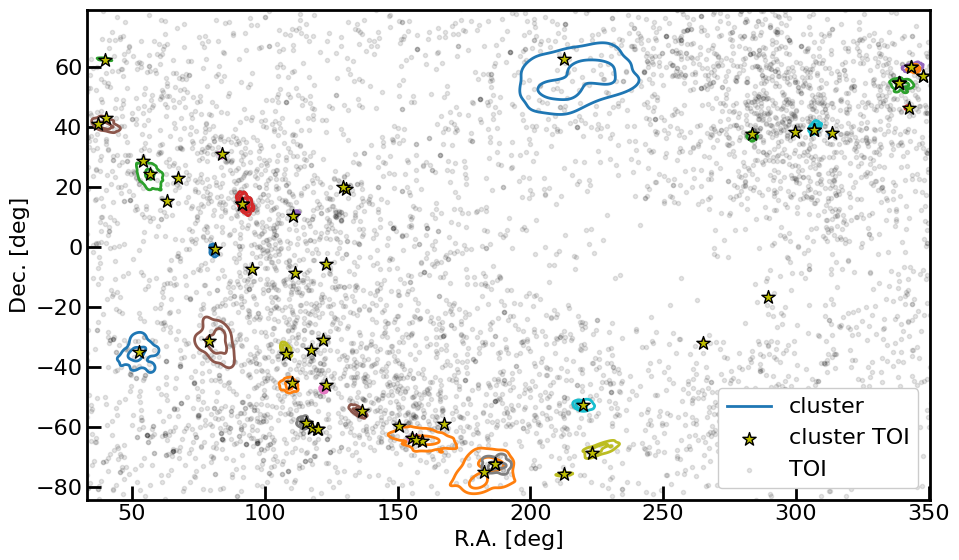

In [71]:
ax = plot_cluster_density(df_mem2, 
                          cluster_tois,
                          prob_threshold=0.1, 
                          bandwidth=1, 
                          min_members=10,
                          plot_all_toi=True
                         )
ax.set_xlabel('R.A. [deg]')
ax.set_ylabel('Dec. [deg]')
ax.figure.savefig('TOI_in_Perren2023.pdf', bbox_inches='tight', dpi=200)